In [1]:
import pandas as pd
import numpy as np

sales = pd.read_csv("../data/processed/clean_sales.csv")

sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

print("Dataset loaded successfully!")
print("Shape:", sales.shape)

Dataset loaded successfully!
Shape: (524878, 9)


C:\Users\sindh\AppData\Local\Temp\ipykernel_14124\1426956176.py:4: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv("../data/processed/clean_sales.csv")


In [2]:
# Core business KPIs

total_revenue = sales["Revenue"].sum()
total_orders = sales["InvoiceNo"].nunique()
total_products = sales["StockCode"].nunique()
total_units = sales["Quantity"].sum()
total_customers = sales["CustomerID"].nunique()
average_order_value = total_revenue / total_orders

print("===== CORE BUSINESS KPIs =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Products: {total_products:,}")
print(f"Units Sold: {total_units:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

===== CORE BUSINESS KPIs =====
Total Revenue: £10,642,110.80
Total Orders: 19,962
Unique Products: 3,922
Units Sold: 5,572,420
Unique Customers: 4,338
Average Order Value: £533.12


In [3]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Unique Products",
        "Units Sold",
        "Unique Customers",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_products,
        total_units,
        total_customers,
        average_order_value
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Revenue,1.064211e+07
1,Total Orders,1.996200e+04
2,Unique Products,3.922000e+03
3,Units Sold,5.572420e+06
4,Unique Customers,4.338000e+03
5,Average Order Value,5.331185e+02


In [4]:
# Create monthly analysis fields

sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

monthly_metrics = (
    sales.groupby("YearMonth")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

monthly_metrics["AOV"] = (
    monthly_metrics["Revenue"] /
    monthly_metrics["Orders"]
)

monthly_metrics

,YearMonth,Revenue,Orders,Units,Customers,AOV
0,2010-12,821452.730,1559,358019,885,526.910026
1,2011-01,689811.610,1086,387099,741,635.185645
2,2011-02,522545.560,1100,282934,758,475.041418
3,2011-03,716215.260,1454,376599,974,492.582710
4,2011-04,536968.491,1246,307953,856,430.953845
5,2011-05,769296.610,1681,395001,1056,457.642243
6,2011-06,760547.010,1533,388511,991,496.116771
7,2011-07,718076.121,1476,399693,949,486.501437
8,2011-08,757841.380,1361,421020,935,556.826877
9,2011-09,1056435.192,1838,569573,1266,574.774316


In [5]:
# Calculate month-over-month growth

monthly_metrics["Revenue_Growth_%"] = (
    monthly_metrics["Revenue"]
    .pct_change() * 100
)

monthly_metrics["Order_Growth_%"] = (
    monthly_metrics["Orders"]
    .pct_change() * 100
)

display(monthly_metrics)

,YearMonth,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%
0,2010-12,821452.730,1559,358019,885,526.910026,NaN,NaN
1,2011-01,689811.610,1086,387099,741,635.185645,-16.025404,-30.339962
2,2011-02,522545.560,1100,282934,758,475.041418,-24.248077,1.289134
3,2011-03,716215.260,1454,376599,974,492.582710,37.062740,32.181818
4,2011-04,536968.491,1246,307953,856,430.953845,-25.026941,-14.305365
5,2011-05,769296.610,1681,395001,1056,457.642243,43.266620,34.911717
6,2011-06,760547.010,1533,388511,991,496.116771,-1.137351,-8.804283
7,2011-07,718076.121,1476,399693,949,486.501437,-5.584256,-3.718200
8,2011-08,757841.380,1361,421020,935,556.826877,5.537750,-7.791328
9,2011-09,1056435.192,1838,569573,1266,574.774316,39.400568,35.047759


In [6]:
# Highest and lowest revenue months

highest_revenue_month = monthly_metrics.loc[
    monthly_metrics["Revenue"].idxmax()
]

lowest_revenue_month = monthly_metrics.loc[
    monthly_metrics["Revenue"].idxmin()
]

print("Highest revenue month:")
display(highest_revenue_month.to_frame().T)

print("\nLowest revenue month:")
display(lowest_revenue_month.to_frame().T)

Highest revenue month:


,YearMonth,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%
11,2011-11,1503866.78,2769,751377,1664,543.108263,30.627478,35.735294



Lowest revenue month:


,YearMonth,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%
2,2011-02,522545.56,1100,282934,758,475.041418,-24.248077,1.289134


In [7]:
# Largest month-over-month movements

growth_data = monthly_metrics.dropna(
    subset=["Revenue_Growth_%"]
)

largest_growth = growth_data.loc[
    growth_data["Revenue_Growth_%"].idxmax()
]

largest_decline = growth_data.loc[
    growth_data["Revenue_Growth_%"].idxmin()
]

print("Largest revenue growth:")
display(largest_growth.to_frame().T)

print("\nLargest revenue decline:")
display(largest_decline.to_frame().T)

Largest revenue growth:


,YearMonth,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%
5,2011-05,769296.61,1681,395001,1056,457.642243,43.26662,34.911717



Largest revenue decline:


,YearMonth,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%
12,2011-12,637790.33,819,313612,615,778.742772,-57.589972,-70.422535


Matplotlib is building the font cache; this may take a moment.


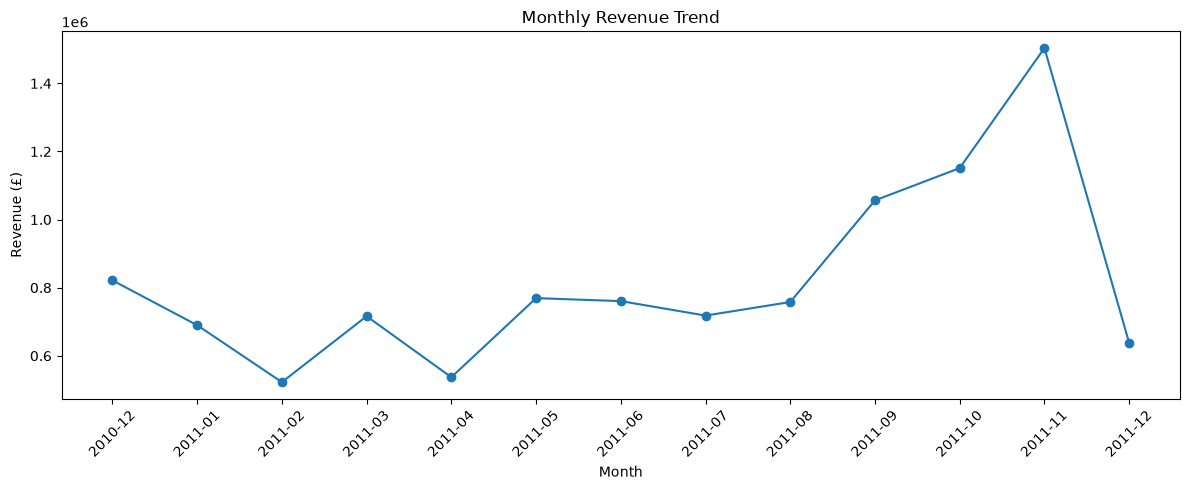

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_metrics["YearMonth"].astype(str),
    monthly_metrics["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Select November 2011 sales

november_sales = sales[
    (sales["InvoiceDate"].dt.year == 2011) &
    (sales["InvoiceDate"].dt.month == 11)
].copy()

print("November 2011 rows:", len(november_sales))
print("November 2011 revenue: £{:,.2f}".format(
    november_sales["Revenue"].sum()
))

November 2011 rows: 82004
November 2011 revenue: £1,503,866.78


In [10]:
# Top products by revenue in November 2011

november_products = (
    november_sales
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

display(november_products.head(15))

,StockCode,Description,Revenue,Units,Orders
2970,DOT,DOTCOM POSTAGE,36905.40,47,47
1615,23084,RABBIT NIGHT LIGHT,34478.40,14913,487
761,22086,PAPER CHAIN KIT 50'S CHRISTMAS,28955.54,7898,390
852,22197,POPCORN HOLDER,14188.80,12452,244
2670,85123A,WHITE HANGING HEART T-LIGHT HOLDER,14130.80,4908,250
1036,22423,REGENCY CAKESTAND 3 TIER,13774.08,1052,201
1458,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,12929.74,3822,276
1872,23355,HOT WATER BOTTLE KEEP CALM,11760.07,2349,288
2658,85099B,JUMBO BAG RED RETROSPOT,11639.29,5908,247
2374,79321,CHILLI LIGHTS,11485.77,2092,114


In [11]:
# Revenue contribution of top products

november_products["Revenue_Share_%"] = (
    november_products["Revenue"] /
    november_products["Revenue"].sum()
) * 100

display(
    november_products[
        ["StockCode", "Description", "Revenue",
         "Revenue_Share_%", "Units", "Orders"]
    ].head(15)
)

,StockCode,Description,Revenue,Revenue_Share_%,Units,Orders
2970,DOT,DOTCOM POSTAGE,36905.40,2.454034,47,47
1615,23084,RABBIT NIGHT LIGHT,34478.40,2.292650,14913,487
761,22086,PAPER CHAIN KIT 50'S CHRISTMAS,28955.54,1.925406,7898,390
852,22197,POPCORN HOLDER,14188.80,0.943488,12452,244
2670,85123A,WHITE HANGING HEART T-LIGHT HOLDER,14130.80,0.939631,4908,250
1036,22423,REGENCY CAKESTAND 3 TIER,13774.08,0.915911,1052,201
1458,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,12929.74,0.859766,3822,276
1872,23355,HOT WATER BOTTLE KEEP CALM,11760.07,0.781989,2349,288
2658,85099B,JUMBO BAG RED RETROSPOT,11639.29,0.773958,5908,247
2374,79321,CHILLI LIGHTS,11485.77,0.763749,2092,114


In [12]:
# Revenue by country in November 2011

november_countries = (
    november_sales
    .groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

display(november_countries.head(15))

,Country,Revenue,Orders,Units,Customers
21,United Kingdom,1319934.07,2490,651942,1505
8,France,31696.37,64,17858,39
6,EIRE,30713.43,42,16655,2
9,Germany,27967.68,68,13435,44
14,Netherlands,25874.01,15,18663,4
18,Spain,8669.06,14,3505,12
12,Japan,8460.08,2,4250,2
20,Switzerland,8118.96,6,3777,4
0,Australia,7242.72,6,4098,3
15,Norway,6527.50,5,3406,5


In [13]:
# Country revenue contribution

november_countries["Revenue_Share_%"] = (
    november_countries["Revenue"] /
    november_countries["Revenue"].sum()
) * 100

display(
    november_countries.head(15)
)

,Country,Revenue,Orders,Units,Customers,Revenue_Share_%
21,United Kingdom,1319934.07,2490,651942,1505,87.769348
8,France,31696.37,64,17858,39,2.107658
6,EIRE,30713.43,42,16655,2,2.042297
9,Germany,27967.68,68,13435,44,1.859718
14,Netherlands,25874.01,15,18663,4,1.720499
18,Spain,8669.06,14,3505,12,0.576451
12,Japan,8460.08,2,4250,2,0.562555
20,Switzerland,8118.96,6,3777,4,0.539872
0,Australia,7242.72,6,4098,3,0.481606
15,Norway,6527.50,5,3406,5,0.434048


In [14]:
# Compare October, November and December 2011

comparison_months = sales[
    (sales["InvoiceDate"] >= "2011-10-01") &
    (sales["InvoiceDate"] < "2012-01-01")
].copy()

monthly_comparison = (
    comparison_months
    .groupby(comparison_months["InvoiceDate"].dt.to_period("M"))
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

monthly_comparison["AOV"] = (
    monthly_comparison["Revenue"] /
    monthly_comparison["Orders"]
)

display(monthly_comparison)

,InvoiceDate,Revenue,Orders,Units,Customers,AOV
0,2011-10,1151263.73,2040,621029,1364,564.344966
1,2011-11,1503866.78,2769,751377,1664,543.108263
2,2011-12,637790.33,819,313612,615,778.742772


In [15]:
# Calculate month-over-month changes

monthly_comparison["Revenue_Growth_%"] = (
    monthly_comparison["Revenue"].pct_change() * 100
)

monthly_comparison["Order_Growth_%"] = (
    monthly_comparison["Orders"].pct_change() * 100
)

monthly_comparison["Unit_Growth_%"] = (
    monthly_comparison["Units"].pct_change() * 100
)

display(monthly_comparison)

,InvoiceDate,Revenue,Orders,Units,Customers,AOV,Revenue_Growth_%,Order_Growth_%,Unit_Growth_%
0,2011-10,1151263.73,2040,621029,1364,564.344966,NaN,NaN,NaN
1,2011-11,1503866.78,2769,751377,1664,543.108263,30.627478,35.735294,20.989036
2,2011-12,637790.33,819,313612,615,778.742772,-57.589972,-70.422535,-58.261698


In [18]:
# Product-level revenue comparison

product_monthly = (
    comparison_months
    .groupby([
        comparison_months["InvoiceDate"].dt.to_period("M"),
        "StockCode",
        "Description"
    ])
    .agg(
        Revenue=("Revenue", "sum"),
        Units=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

product_pivot = product_monthly.pivot_table(
    index=["StockCode", "Description"],
    columns="InvoiceDate",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

# Use Period objects, not strings
oct_2011 = pd.Period("2011-10", freq="M")
nov_2011 = pd.Period("2011-11", freq="M")
dec_2011 = pd.Period("2011-12", freq="M")

product_pivot["Oct_to_Nov_Change"] = (
    product_pivot.get(nov_2011, 0) -
    product_pivot.get(oct_2011, 0)
)

product_pivot["Nov_to_Dec_Change"] = (
    product_pivot.get(dec_2011, 0) -
    product_pivot.get(nov_2011, 0)
)

display(
    product_pivot
    .sort_values("Oct_to_Nov_Change", ascending=False)
    .head(15)
)


,InvoiceDate,2011-10,2011-11,2011-12,Oct_to_Nov_Change,Nov_to_Dec_Change
StockCode,Description,,,,,
23084,RABBIT NIGHT LIGHT,12256.87,34478.40,9628.46,22221.53,-24849.94
DOT,DOTCOM POSTAGE,17955.13,36905.40,19872.69,18950.27,-17032.71
22086,PAPER CHAIN KIT 50'S CHRISTMAS,10022.54,28955.54,6867.76,18933.00,-22087.78
85123A,WHITE HANGING HEART T-LIGHT HOLDER,4750.15,14130.80,2047.90,9380.65,-12082.90
22197,POPCORN HOLDER,4810.55,14188.80,5423.80,9378.25,-8765.00
22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,4833.97,12929.74,2760.61,8095.77,-10169.13
79321,CHILLI LIGHTS,4678.13,11485.77,2639.74,6807.64,-8846.03
23344,JUMBO BAG 50'S CHRISTMAS,4895.27,11062.98,2244.95,6167.71,-8818.03
23581,JUMBO BAG PAISLEY PARK,2205.76,7982.30,1393.77,5776.54,-6588.53


In [19]:
# Products with the largest revenue declines from November to December

display(
    product_pivot
    .sort_values("Nov_to_Dec_Change", ascending=True)
    .head(15)
)

,InvoiceDate,2011-10,2011-11,2011-12,Oct_to_Nov_Change,Nov_to_Dec_Change
StockCode,Description,,,,,
23084,RABBIT NIGHT LIGHT,12256.87,34478.40,9628.46,22221.53,-24849.94
22086,PAPER CHAIN KIT 50'S CHRISTMAS,10022.54,28955.54,6867.76,18933.00,-22087.78
DOT,DOTCOM POSTAGE,17955.13,36905.40,19872.69,18950.27,-17032.71
85123A,WHITE HANGING HEART T-LIGHT HOLDER,4750.15,14130.80,2047.90,9380.65,-12082.90
22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,4833.97,12929.74,2760.61,8095.77,-10169.13
85099B,JUMBO BAG RED RETROSPOT,10485.81,11639.29,2226.90,1153.48,-9412.39
79321,CHILLI LIGHTS,4678.13,11485.77,2639.74,6807.64,-8846.03
23344,JUMBO BAG 50'S CHRISTMAS,4895.27,11062.98,2244.95,6167.71,-8818.03
22197,POPCORN HOLDER,4810.55,14188.80,5423.80,9378.25,-8765.00


In [20]:
# Total October to November revenue change

oct_revenue = monthly_comparison.loc[
    monthly_comparison["InvoiceDate"] == pd.Period("2011-10", freq="M"),
    "Revenue"
].iloc[0]

nov_revenue = monthly_comparison.loc[
    monthly_comparison["InvoiceDate"] == pd.Period("2011-11", freq="M"),
    "Revenue"
].iloc[0]

dec_revenue = monthly_comparison.loc[
    monthly_comparison["InvoiceDate"] == pd.Period("2011-12", freq="M"),
    "Revenue"
].iloc[0]

oct_nov_change = nov_revenue - oct_revenue
nov_dec_change = dec_revenue - nov_revenue

print(f"October → November revenue change: £{oct_nov_change:,.2f}")
print(f"November → December revenue change: £{nov_dec_change:,.2f}")

October → November revenue change: £352,603.05
November → December revenue change: £-866,076.45


In [21]:
# Top products contributing to October → November growth

growth_contributors = (
    product_pivot[
        product_pivot["Oct_to_Nov_Change"] > 0
    ]
    .sort_values("Oct_to_Nov_Change", ascending=False)
    .copy()
)

growth_contributors["Contribution_to_Total_Growth_%"] = (
    growth_contributors["Oct_to_Nov_Change"] /
    oct_nov_change
) * 100

display(
    growth_contributors[
        [
            "Oct_to_Nov_Change",
            "Contribution_to_Total_Growth_%"
        ]
    ].head(15)
)

,InvoiceDate,Oct_to_Nov_Change,Contribution_to_Total_Growth_%
StockCode,Description,,
23084,RABBIT NIGHT LIGHT,22221.53,6.302138
DOT,DOTCOM POSTAGE,18950.27,5.374392
22086,PAPER CHAIN KIT 50'S CHRISTMAS,18933.00,5.369494
85123A,WHITE HANGING HEART T-LIGHT HOLDER,9380.65,2.660400
22197,POPCORN HOLDER,9378.25,2.659719
22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,8095.77,2.296001
79321,CHILLI LIGHTS,6807.64,1.930681
23344,JUMBO BAG 50'S CHRISTMAS,6167.71,1.749194
23581,JUMBO BAG PAISLEY PARK,5776.54,1.638256


In [22]:
# Products contributing to November → December decline

decline_contributors = (
    product_pivot[
        product_pivot["Nov_to_Dec_Change"] < 0
    ]
    .sort_values("Nov_to_Dec_Change")
    .copy()
)

decline_contributors["Contribution_to_Total_Decline_%"] = (
    decline_contributors["Nov_to_Dec_Change"].abs() /
    abs(nov_dec_change)
) * 100

display(
    decline_contributors[
        [
            "Nov_to_Dec_Change",
            "Contribution_to_Total_Decline_%"
        ]
    ].head(15)
)

,InvoiceDate,Nov_to_Dec_Change,Contribution_to_Total_Decline_%
StockCode,Description,,
23084,RABBIT NIGHT LIGHT,-24849.94,2.869255
22086,PAPER CHAIN KIT 50'S CHRISTMAS,-22087.78,2.550327
DOT,DOTCOM POSTAGE,-17032.71,1.966652
85123A,WHITE HANGING HEART T-LIGHT HOLDER,-12082.90,1.395131
22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,-10169.13,1.174161
85099B,JUMBO BAG RED RETROSPOT,-9412.39,1.086785
79321,CHILLI LIGHTS,-8846.03,1.021391
23344,JUMBO BAG 50'S CHRISTMAS,-8818.03,1.018158
22197,POPCORN HOLDER,-8765.00,1.012035


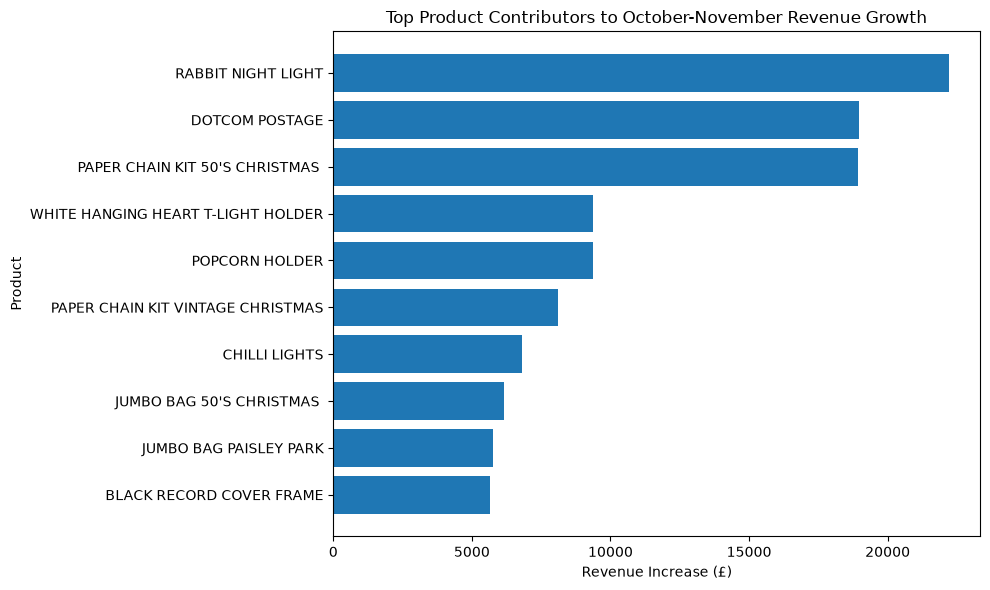

In [25]:
# Top 10 products contributing to October-November growth

top_growth = (
    growth_contributors
    .head(10)
    .sort_values("Oct_to_Nov_Change")
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_growth["Description"],
    top_growth["Oct_to_Nov_Change"]
)

plt.title("Top Product Contributors to October-November Revenue Growth")
plt.xlabel("Revenue Increase (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

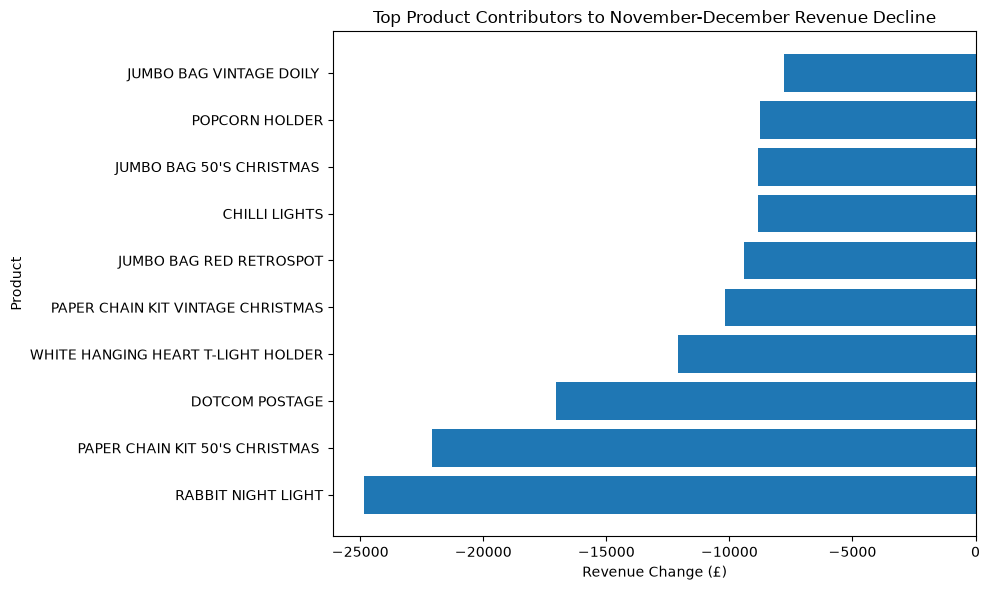

In [26]:
# Top 10 products contributing to November-December decline

top_decline = (
    decline_contributors
    .head(10)
    .sort_values("Nov_to_Dec_Change")
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_decline["Description"],
    top_decline["Nov_to_Dec_Change"]
)

plt.title("Top Product Contributors to November-December Revenue Decline")
plt.xlabel("Revenue Change (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [27]:
# Monthly country-level revenue

country_monthly = (
    sales
    .groupby([
        sales["InvoiceDate"].dt.to_period("M"),
        "Country"
    ])
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum")
    )
    .reset_index()
)

display(country_monthly.head())

,InvoiceDate,Country,Revenue,Orders,Units
0,2010-12,Australia,965.35,3,457
1,2010-12,Austria,277.20,1,51
2,2010-12,Bahrain,205.74,1,54
3,2010-12,Belgium,1809.91,5,1755
4,2010-12,Channel Islands,363.53,1,80


In [28]:
# Pivot country revenue across the three months

country_pivot = country_monthly.pivot_table(
    index="Country",
    columns="InvoiceDate",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

oct_2011 = pd.Period("2011-10", freq="M")
nov_2011 = pd.Period("2011-11", freq="M")
dec_2011 = pd.Period("2011-12", freq="M")

country_pivot["Oct_to_Nov_Change"] = (
    country_pivot.get(nov_2011, 0) -
    country_pivot.get(oct_2011, 0)
)

country_pivot["Nov_to_Dec_Change"] = (
    country_pivot.get(dec_2011, 0) -
    country_pivot.get(nov_2011, 0)
)

display(
    country_pivot
    .sort_values("Oct_to_Nov_Change", ascending=False)
    .head(15)
)

InvoiceDate,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12,Oct_to_Nov_Change,Nov_to_Dec_Change
Country,,,,,,,,,,,,,,,
United Kingdom,746082.22,559975.83,428986.62,584810.78,475677.631,638104.89,618345.53,600919.071,606784.93,895098.642,935404.14,1319934.07,591619.74,384529.93,-728314.33
Japan,7705.07,0.00,5780.81,48.90,6548.500,1351.45,1607.04,3854.400,0.00,112.080,1948.04,8460.08,0.00,6512.04,-8460.08
EIRE,10033.26,21904.19,12203.74,22197.51,7570.500,18003.72,24863.61,42738.850,18344.20,42923.700,24302.92,30713.43,7340.89,6410.51,-23372.54
Norway,3787.12,0.00,630.90,1265.31,0.000,0.00,5886.86,890.070,2025.81,8678.940,3687.23,6527.50,2785.70,2840.27,-3741.80
Poland,248.16,613.22,604.05,317.78,705.840,1522.37,343.65,687.300,401.80,529.250,0.00,1361.23,0.00,1361.23,-1361.23
Denmark,1281.50,0.00,399.22,3978.99,0.000,515.70,3261.15,376.240,213.15,4570.160,1490.76,2699.57,168.90,1208.81,-2530.67
Italy,811.50,2402.51,256.00,1806.81,737.830,587.45,202.07,147.100,1990.95,279.800,3489.69,4571.08,200.45,1081.39,-4370.63
Unspecified,0.00,0.00,0.00,0.00,299.100,1055.87,185.78,1419.110,531.03,284.300,0.00,965.75,0.00,965.75,-965.75
Malta,0.00,0.00,0.00,0.00,0.000,0.00,863.16,0.000,1119.00,0.000,0.00,743.43,0.00,743.43,-743.43


In [29]:
# Countries contributing to October-November growth

country_growth = (
    country_pivot[
        country_pivot["Oct_to_Nov_Change"] > 0
    ]
    .sort_values("Oct_to_Nov_Change", ascending=False)
    .copy()
)

country_growth["Growth_Contribution_%"] = (
    country_growth["Oct_to_Nov_Change"] /
    oct_nov_change
) * 100

display(country_growth.head(15))

InvoiceDate,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12,Oct_to_Nov_Change,Nov_to_Dec_Change,Growth_Contribution_%
Country,,,,,,,,,,,,,,,,
United Kingdom,746082.22,559975.83,428986.62,584810.78,475677.631,638104.89,618345.53,600919.071,606784.93,895098.642,935404.14,1319934.07,591619.74,384529.93,-728314.33,109.054624
Japan,7705.07,0.00,5780.81,48.90,6548.500,1351.45,1607.04,3854.400,0.00,112.080,1948.04,8460.08,0.00,6512.04,-8460.08,1.846847
EIRE,10033.26,21904.19,12203.74,22197.51,7570.500,18003.72,24863.61,42738.850,18344.20,42923.700,24302.92,30713.43,7340.89,6410.51,-23372.54,1.818053
Norway,3787.12,0.00,630.90,1265.31,0.000,0.00,5886.86,890.070,2025.81,8678.940,3687.23,6527.50,2785.70,2840.27,-3741.80,0.805515
Poland,248.16,613.22,604.05,317.78,705.840,1522.37,343.65,687.300,401.80,529.250,0.00,1361.23,0.00,1361.23,-1361.23,0.386052
Denmark,1281.50,0.00,399.22,3978.99,0.000,515.70,3261.15,376.240,213.15,4570.160,1490.76,2699.57,168.90,1208.81,-2530.67,0.342825
Italy,811.50,2402.51,256.00,1806.81,737.830,587.45,202.07,147.100,1990.95,279.800,3489.69,4571.08,200.45,1081.39,-4370.63,0.306688
Unspecified,0.00,0.00,0.00,0.00,299.100,1055.87,185.78,1419.110,531.03,284.300,0.00,965.75,0.00,965.75,-965.75,0.273892
Malta,0.00,0.00,0.00,0.00,0.000,0.00,863.16,0.000,1119.00,0.000,0.00,743.43,0.00,743.43,-743.43,0.210840


In [30]:
# Countries contributing to November-December decline

country_decline = (
    country_pivot[
        country_pivot["Nov_to_Dec_Change"] < 0
    ]
    .sort_values("Nov_to_Dec_Change")
    .copy()
)

country_decline["Decline_Contribution_%"] = (
    country_decline["Nov_to_Dec_Change"].abs() /
    abs(nov_dec_change)
) * 100

display(country_decline.head(15))

InvoiceDate,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12,Oct_to_Nov_Change,Nov_to_Dec_Change,Decline_Contribution_%
Country,,,,,,,,,,,,,,,,
United Kingdom,746082.22,559975.83,428986.62,584810.78,475677.631,638104.89,618345.53,600919.071,606784.93,895098.642,935404.14,1319934.07,591619.74,384529.93,-728314.33,84.093538
France,9616.31,17740.12,8515.96,14584.95,5529.610,17606.48,16348.41,10000.190,13810.96,23428.040,33471.05,31696.37,7276.92,-1774.68,-24419.45,2.819549
EIRE,10033.26,21904.19,12203.74,22197.51,7570.500,18003.72,24863.61,42738.850,18344.20,42923.700,24302.92,30713.43,7340.89,6410.51,-23372.54,2.698669
Germany,15205.74,16880.84,9581.05,14392.69,12315.540,25734.70,13246.35,16440.980,19220.77,18079.470,31628.42,27967.68,7984.17,-3660.74,-19983.51,2.307361
Netherlands,8784.48,26611.16,23011.91,22416.49,2976.560,29185.88,26858.09,26.020,40327.81,26937.260,40708.65,25874.01,11728.02,-14834.64,-14145.99,1.633342
Japan,7705.07,0.00,5780.81,48.90,6548.500,1351.45,1607.04,3854.400,0.00,112.080,1948.04,8460.08,0.00,6512.04,-8460.08,0.976828
Spain,1843.73,10086.09,2114.50,5363.15,1785.650,3257.60,3333.21,7620.770,3342.41,5189.240,8636.94,8669.06,316.21,32.12,-8352.85,0.964447
Switzerland,1304.92,4231.23,2654.92,1870.23,2076.940,3610.01,7904.15,3990.760,4969.89,8284.860,8050.73,8118.96,0.00,68.23,-8118.96,0.937441
Australia,965.35,9017.71,14695.42,17223.99,771.600,13638.41,25187.77,4964.380,22489.20,5106.730,17150.53,7242.72,0.00,-9907.81,-7242.72,0.836268


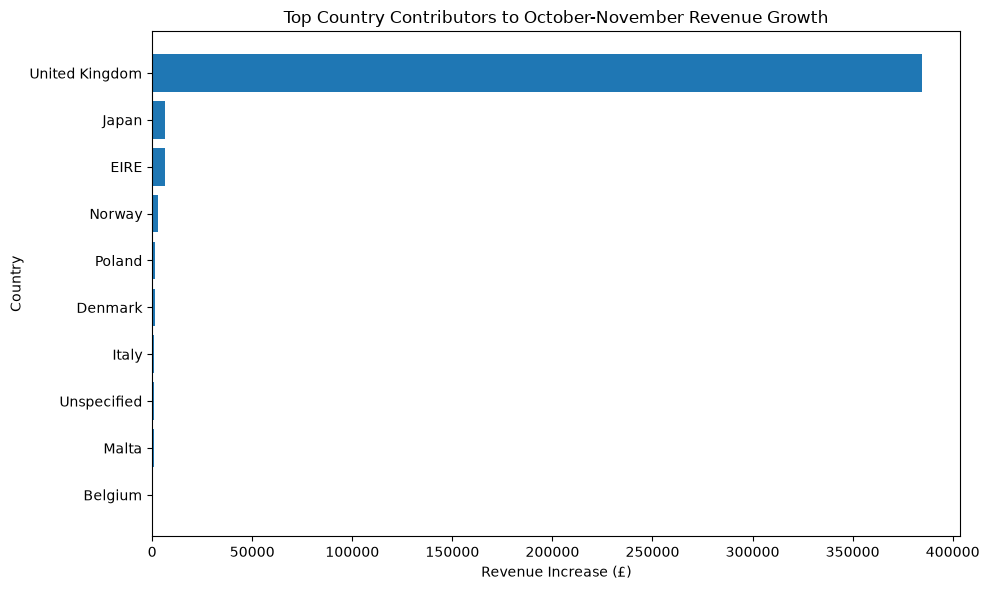

In [31]:
# Top countries driving October-November growth

top_country_growth = (
    country_growth
    .head(10)
    .sort_values("Oct_to_Nov_Change")
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_country_growth["Country"],
    top_country_growth["Oct_to_Nov_Change"]
)

plt.title("Top Country Contributors to October-November Revenue Growth")
plt.xlabel("Revenue Increase (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

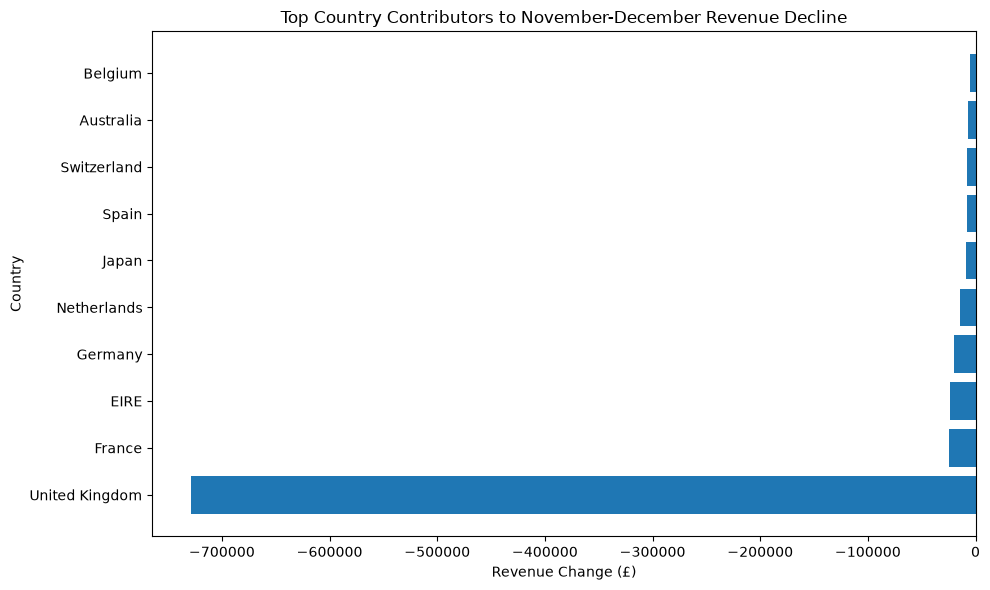

In [32]:
# Top countries driving November-December decline

top_country_decline = (
    country_decline
    .head(10)
    .sort_values("Nov_to_Dec_Change")
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_country_decline["Country"],
    top_country_decline["Nov_to_Dec_Change"]
)

plt.title("Top Country Contributors to November-December Revenue Decline")
plt.xlabel("Revenue Change (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [35]:
# Load cancellation data

cancellations = pd.read_csv(
    "../data/processed/cancellations.csv"
)

cancellations["InvoiceDate"] = pd.to_datetime(
    cancellations["InvoiceDate"]
)

print("Cancellation dataset loaded.")
print("Shape:", cancellations.shape)

display(cancellations.head())

Cancellation dataset loaded.
Shape: (9288, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
1,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
2,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
3,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
4,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96


In [36]:
# Product-level cancellation metrics

cancellation_product = (
    cancellations
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Cancellation_Units=("Quantity", lambda x: x.abs().sum()),
        Cancellation_Transactions=("InvoiceNo", "nunique"),
        Cancellation_Value=("Revenue", lambda x: x.abs().sum())
    )
    .reset_index()
)

print("Products with cancellation records:", len(cancellation_product))

display(
    cancellation_product
    .sort_values("Cancellation_Units", ascending=False)
    .head(20)
)

Products with cancellation records: 1975


,StockCode,Description,Cancellation_Units,Cancellation_Transactions,Cancellation_Value
1529,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
1270,23166,MEDIUM CERAMIC TOP STORAGE JAR,74494,10,77479.64
1688,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9376,4,321.60
1972,M,Manual,4066,223,146784.46
133,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150,3,6591.42
96,20971,PINK BLUE FELT CRAFT TRINKET BOX,2617,4,2778.77
1859,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2578,42,6624.30
158,21175,GIN + TONIC DIET METAL SIGN,2030,7,3775.33
1079,22920,HERB MARKER BASIL,1527,2,841.05
624,22273,FELTCRAFT DOLL MOLLY,1447,5,3512.65


In [37]:
# Combine product sales and cancellation metrics

product_performance = product_performance.merge(
    cancellation_product,
    on=["StockCode", "Description"],
    how="left"
)

product_performance[
    [
        "Cancellation_Units",
        "Cancellation_Transactions",
        "Cancellation_Value"
    ]
] = product_performance[
    [
        "Cancellation_Units",
        "Cancellation_Transactions",
        "Cancellation_Value"
    ]
].fillna(0)

display(product_performance.head())

,StockCode,Description,Revenue,Units_Sold,Orders,Avg_Unit_Price,Cancellation_Units,Cancellation_Transactions,Cancellation_Value
0,10002,INFLATABLE POLITICAL GLOBE,759.89,860,71,1.086620,0.0,0.0,0.0
1,10080,GROOVY CACTUS INFLATABLE,119.09,303,22,0.410909,0.0,0.0,0.0
2,10120,DOGGY RUBBER,40.32,192,29,0.210000,0.0,0.0,0.0
3,10123C,HEARTS WRAPPING TAPE,3.25,5,3,0.650000,0.0,0.0,0.0
4,10124A,SPOTS ON RED BOOKCOVER TAPE,6.72,16,5,0.420000,0.0,0.0,0.0


In [38]:
# Calculate cancellation rate

product_performance["Cancellation_Rate_%"] = (
    product_performance["Cancellation_Units"] /
    (
        product_performance["Units_Sold"] +
        product_performance["Cancellation_Units"]
    )
) * 100

display(
    product_performance
    .sort_values("Cancellation_Rate_%", ascending=False)
    .head(20)
)

,StockCode,Description,Revenue,Units_Sold,Orders,Avg_Unit_Price,Cancellation_Units,Cancellation_Transactions,Cancellation_Value,Cancellation_Rate_%
4154,S,SAMPLES,63.050,2,2,31.525000,61.0,17.0,3112.44,96.825397
4139,AMAZONFEE,AMAZON FEE,13761.090,2,2,6880.545000,32.0,32.0,235281.59,94.117647
166,20703,BLUE PADDED SOFT MOBILE,4.250,1,1,4.250000,7.0,3.0,29.75,87.500000
399,21144,PINK POODLE HANGING DECORATION,16.800,5,2,3.360000,12.0,1.0,4.56,70.588235
4141,BANK CHARGES,Bank Charges,165.001,12,11,13.750083,25.0,25.0,7340.64,67.567568
3061,79323P,PINK CHERRY LIGHTS,27.000,4,1,6.750000,8.0,2.0,54.00,66.666667
2680,35400,WOODEN BOX ADVENT CALENDAR,89.500,10,5,8.950000,16.0,8.0,135.20,61.538462
3009,72815,3 WICK CHRISTMAS BRIAR CANDLE,15.970,3,2,6.110000,4.0,1.0,15.00,57.142857
974,22034,ROBIN CHRISTMAS CARD,5.020,10,4,0.625000,12.0,1.0,5.04,54.545455
3333,84750A,PINK SMALL GLASS CAKE STAND,46.800,24,1,1.950000,27.0,2.0,52.65,52.941176


In [39]:
# High-volume products with elevated cancellation rates

high_volume_products = product_performance[
    product_performance["Units_Sold"] >= 100
].copy()

high_volume_products = (
    high_volume_products
    .sort_values("Cancellation_Rate_%", ascending=False)
)

display(
    high_volume_products[
        [
            "StockCode",
            "Description",
            "Units_Sold",
            "Revenue",
            "Cancellation_Units",
            "Cancellation_Rate_%"
        ]
    ].head(20)
)

,StockCode,Description,Units_Sold,Revenue,Cancellation_Units,Cancellation_Rate_%
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,80995.0,50.000000
3163,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9461,26425.58,9376.0,49.774380
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,74494.0,48.839878
3755,85232B,SET OF 3 BABUSHKA STACKING TINS,274,1356.30,255.0,48.204159
2061,23113,PANTRY CHOPPING BOARD,1154,5868.50,946.0,45.047619
3537,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,235.35,73.0,41.011236
1993,23055,IVORY CHANDELIER T-LIGHT HOLDER,657,1395.18,432.0,39.669421
1996,23057,BEADED CHANDELIER T-LIGHT HOLDER,695,1420.97,433.0,38.386525
1995,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,960,2879.37,579.0,37.621832
2878,47566B,TEA TIME PARTY BUNTING,2379,11275.27,1424.0,37.444123


In [40]:
# High-revenue products and their cancellation exposure

high_revenue_products = (
    product_performance
    .sort_values("Revenue", ascending=False)
    .head(30)
)

display(
    high_revenue_products[
        [
            "StockCode",
            "Description",
            "Revenue",
            "Units_Sold",
            "Orders",
            "Avg_Unit_Price",
            "Cancellation_Units",
            "Cancellation_Rate_%"
        ]
    ]
)

,StockCode,Description,Revenue,Units_Sold,Orders,Avg_Unit_Price,Cancellation_Units,Cancellation_Rate_%
4150,DOT,DOTCOM POSTAGE,206248.77,706,706,292.137068,1.0,0.141443
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,13.983936,857.0,5.826761
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,2.080000,80995.0,50.000000
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189,3.116159,2578.0,6.419642
2877,47566,PARTY BUNTING,99445.23,18283,1685,5.797928,277.0,1.492457
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,2.486197,1115.0,2.253163
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,1.468480,74494.0,48.839878
4153,POST,POSTAGE,78101.88,3150,1126,31.076581,147.0,4.458599
4151,M,Manual,77750.27,6984,289,234.489652,4066.0,36.796380
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,2.386401,108.0,0.350115


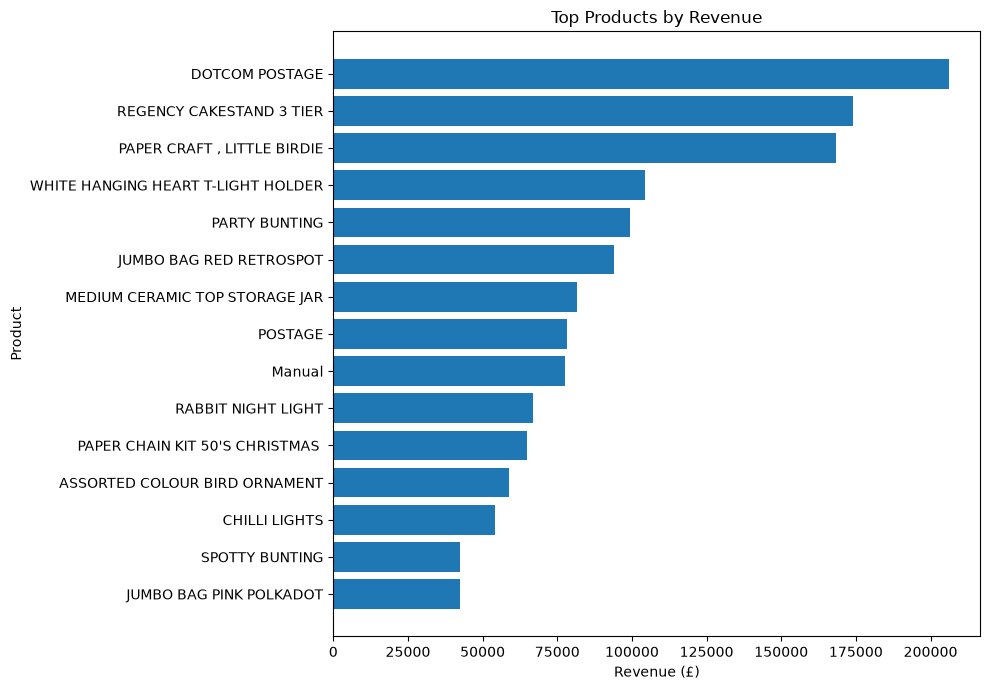

In [41]:
top_products = (
    product_performance
    .sort_values("Revenue", ascending=False)
    .head(15)
    .sort_values("Revenue")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_products["Description"],
    top_products["Revenue"]
)

plt.title("Top Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [42]:
# Save product performance dataset

product_performance.to_csv(
    "../data/processed/product_performance.csv",
    index=False
)

print("Saved product_performance.csv")
print("Rows:", len(product_performance))

Saved product_performance.csv
Rows: 4161


In [43]:
# Prepare customer-level dataset

customer_sales = sales[
    sales["CustomerID"].notna()
].copy()

customer_sales["CustomerID"] = (
    customer_sales["CustomerID"].astype(int).astype(str)
)

print("Customer-level transactions:", len(customer_sales))
print("Unique customers:", customer_sales["CustomerID"].nunique())

Customer-level transactions: 392692
Unique customers: 4338


In [44]:
# Define reference date

reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [45]:
# Calculate RFM metrics

rfm = (
    customer_sales
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", 
                 lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

display(rfm.head())

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [46]:
# RFM statistics

print("RFM statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272245,2048.688081
std,100.014169,7.697975,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [47]:
# Top customers by monetary value

display(
    rfm.sort_values("Monetary", ascending=False).head(20)
)

,CustomerID,Recency,Frequency,Monetary
1689,14646,2,73,280206.02
4201,18102,1,60,259657.30
3728,17450,8,46,194390.79
3008,16446,1,2,168472.50
1879,14911,1,201,143711.17
55,12415,24,21,124914.53
1333,14156,10,55,117210.08
3771,17511,3,31,91062.38
2702,16029,39,63,80850.84
0,12346,326,1,77183.60


In [48]:
# Create RFM scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(20))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112
5,12352,36,8,2506.04,3,5,5,355
6,12353,204,1,89.00,1,1,1,111
7,12354,232,1,1079.40,1,1,4,114
8,12355,214,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


In [49]:
# Create customer segments

def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "High-Value Active"

    elif r >= 4 and f >= 3:
        return "Loyal Active"

    elif r >= 4 and m >= 4:
        return "Recent High-Value"

    elif r <= 2 and f >= 4:
        return "At-Risk Loyal"

    elif r <= 2 and m >= 4:
        return "At-Risk High-Value"

    elif r <= 2:
        return "Inactive"

    else:
        return "Regular"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

display(
    rfm["Segment"]
    .value_counts()
    .to_frame("Customers")
)

,Customers
Segment,
Inactive,1265
Regular,1146
High-Value Active,958
Loyal Active,495
At-Risk Loyal,274
At-Risk High-Value,169
Recent High-Value,31


In [50]:
# Segment-level analysis

segment_analysis = (
    rfm
    .groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Total_Revenue=("Monetary", "sum"),
        Avg_Revenue=("Monetary", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Recency=("Recency", "mean")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

segment_analysis["Revenue_Share_%"] = (
    segment_analysis["Total_Revenue"] /
    segment_analysis["Total_Revenue"].sum()
) * 100

display(segment_analysis)

,Segment,Customers,Total_Revenue,Avg_Revenue,Avg_Frequency,Avg_Recency,Revenue_Share_%
2,High-Value Active,958,5793774.750,6047.781576,11.115866,12.816284,65.192287
6,Regular,1146,1190356.250,1038.705279,2.624782,43.860384,13.394039
4,Loyal Active,495,532392.861,1075.541133,2.951515,16.183838,5.990552
0,At-Risk High-Value,169,458166.251,2711.042905,1.988166,162.023669,5.155345
1,At-Risk Loyal,274,431017.440,1573.056350,4.897810,137.153285,4.849863
3,Inactive,1265,427190.972,337.700373,1.331225,209.784980,4.806807
5,Recent High-Value,31,54310.370,1751.947419,1.709677,17.096774,0.611107


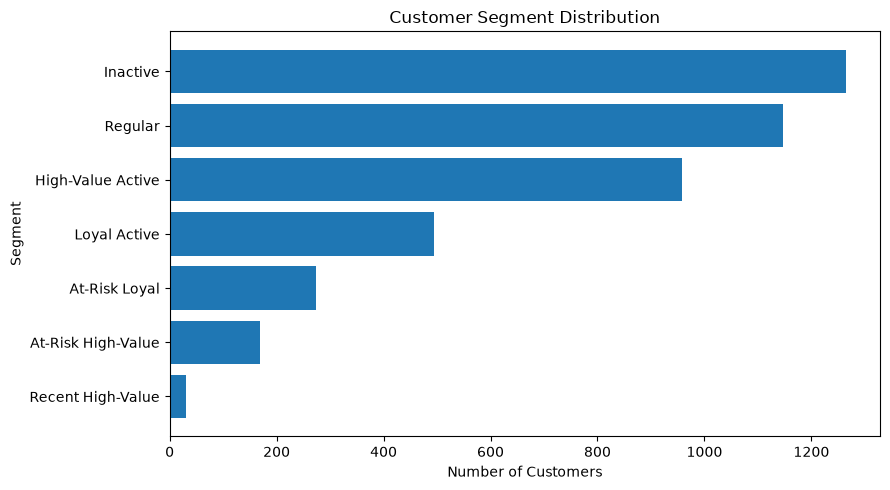

In [51]:
# Customer segment distribution

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.barh(
    segment_counts.index,
    segment_counts.values
)

plt.title("Customer Segment Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Segment")
plt.tight_layout()
plt.show()

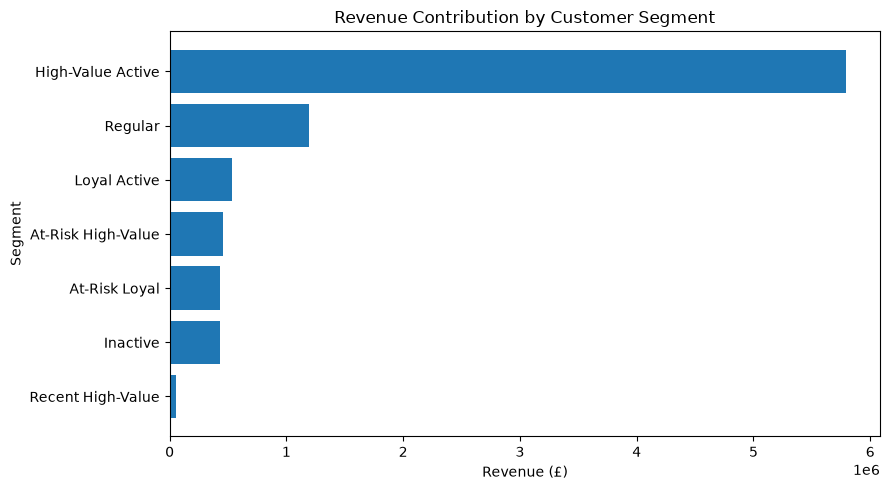

In [52]:
# Revenue by customer segment

segment_revenue = (
    segment_analysis
    .sort_values("Total_Revenue")
)

plt.figure(figsize=(9, 5))

plt.barh(
    segment_revenue["Segment"],
    segment_revenue["Total_Revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Revenue (£)")
plt.ylabel("Segment")
plt.tight_layout()
plt.show()

In [53]:
# Save customer RFM analysis

rfm.to_csv(
    "../data/processed/customer_rfm.csv",
    index=False
)

segment_analysis.to_csv(
    "../data/processed/customer_segments.csv",
    index=False
)

print("Saved:")
print("- customer_rfm.csv")
print("- customer_segments.csv")

Saved:
- customer_rfm.csv
- customer_segments.csv


In [54]:
# Make sure CustomerID has the same format in both datasets

sales_customer = sales[
    sales["CustomerID"].notna()
].copy()

sales_customer["CustomerID"] = (
    sales_customer["CustomerID"]
    .astype(int)
    .astype(str)
)

# Attach RFM segment to each transaction

sales_customer = sales_customer.merge(
    rfm[["CustomerID", "Segment"]],
    on="CustomerID",
    how="left"
)

print("Rows:", len(sales_customer))
print("Missing segments:", sales_customer["Segment"].isna().sum())

display(sales_customer.head())

Rows: 392692
Missing segments: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth,Segment
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,At-Risk Loyal
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,At-Risk Loyal
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,At-Risk Loyal
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,At-Risk Loyal
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,At-Risk Loyal


In [55]:
# Product revenue by customer segment

product_segment = (
    sales_customer
    .groupby(["Segment", "StockCode", "Description"], dropna=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

display(
    product_segment
    .sort_values("Revenue", ascending=False)
    .head(20)
)

,Segment,StockCode,Description,Revenue,Units,Orders,Customers
13772,Loyal Active,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1
6112,High-Value Active,22423,REGENCY CAKESTAND 3 TIER,104927.70,9209,952,324
1468,At-Risk High-Value,23166,MEDIUM CERAMIC TOP STORAGE JAR,77417.19,74418,13,12
8171,High-Value Active,85123A,WHITE HANGING HEART T-LIGHT HOLDER,67540.85,24525,1138,318
8157,High-Value Active,85099B,JUMBO BAG RED RETROSPOT,61314.32,33344,1092,308
7549,High-Value Active,47566,PARTY BUNTING,43408.78,9750,789,287
8538,High-Value Active,POST,POSTAGE,41260.97,2046,670,100
7996,High-Value Active,84879,ASSORTED COLOUR BIRD ORNAMENT,40225.83,25503,774,271
902,At-Risk High-Value,22502,PICNIC BASKET WICKER 60 PIECES,39619.50,61,2,1
6791,High-Value Active,23084,RABBIT NIGHT LIGHT,37169.11,19485,541,241


In [56]:
# Top products within each customer segment

top_products_by_segment = (
    product_segment
    .sort_values(
        ["Segment", "Revenue"],
        ascending=[True, False]
    )
    .groupby("Segment")
    .head(10)
)

display(top_products_by_segment)

,Segment,StockCode,Description,Revenue,Units,Orders,Customers
1468,At-Risk High-Value,23166,MEDIUM CERAMIC TOP STORAGE JAR,77417.19,74418,13,12
902,At-Risk High-Value,22502,PICNIC BASKET WICKER 60 PIECES,39619.50,61,2,1
173,At-Risk High-Value,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,13239.45,6291,9,7
2047,At-Risk High-Value,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10790.80,4306,40,25
1798,At-Risk High-Value,48185,DOORMAT FAIRY CAKE,9004.10,1370,11,9
...,...,...,...,...,...,...,...
16650,Regular,22273,FELTCRAFT DOLL MOLLY,7719.40,3052,71,56
18625,Regular,85123A,WHITE HANGING HEART T-LIGHT HOLDER,7555.15,2661,301,183
18101,Regular,47566,PARTY BUNTING,7467.05,1579,213,135
17043,Regular,22693,GROW A FLYTRAP OR SUNFLOWER IN TIN,7253.67,7371,53,37


In [57]:
# Display top 5 products for every customer segment

for segment in sorted(product_segment["Segment"].dropna().unique()):
    
    print("\n" + "=" * 70)
    print(f"SEGMENT: {segment}")
    print("=" * 70)
    
    display(
        product_segment[
            product_segment["Segment"] == segment
        ]
        .sort_values("Revenue", ascending=False)
        .head(5)
        [
            [
                "StockCode",
                "Description",
                "Revenue",
                "Units",
                "Orders",
                "Customers"
            ]
        ]
    )


SEGMENT: At-Risk High-Value


,StockCode,Description,Revenue,Units,Orders,Customers
1468,23166,MEDIUM CERAMIC TOP STORAGE JAR,77417.19,74418,13,12
902,22502,PICNIC BASKET WICKER 60 PIECES,39619.50,61,2,1
173,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,13239.45,6291,9,7
2047,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10790.80,4306,40,25
1798,48185,DOORMAT FAIRY CAKE,9004.10,1370,11,9



SEGMENT: At-Risk Loyal


,StockCode,Description,Revenue,Units,Orders,Customers
4268,47566,PARTY BUNTING,8761.80,1988,123,68
3244,22423,REGENCY CAKESTAND 3 TIER,6402.40,562,131,72
4700,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6188.80,2256,180,79
4412,84078A,SET/4 WHITE RETRO STORAGE CUBES,5222.55,149,12,4
4820,POST,POSTAGE,3836.94,140,54,15



SEGMENT: High-Value Active


...

,StockCode,Description,Revenue,Units,Orders,Customers
13772,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1
13280,23084,RABBIT NIGHT LIGHT,7952.59,4360,115,87
14317,85099B,JUMBO BAG RED RETROSPOT,3196.62,1716,74,58
12664,22423,REGENCY CAKESTAND 3 TIER,3030.75,249,104,80
12374,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2745.75,985,122,94



SEGMENT: Recent High-Value


,StockCode,Description,Revenue,Units,Orders,Customers
14930,22413,METAL SIGN TAKE IT OR LEAVE IT,3896.4,1416,3,3
15433,23582,VINTAGE DOILY JUMBO BAG RED,2726.6,1520,3,2
15587,POST,POSTAGE,2366.0,71,19,10
15021,22617,BAKING SET SPACEBOY DESIGN,947.7,222,3,3
14937,22423,REGENCY CAKESTAND 3 TIER,561.0,44,16,12



SEGMENT: Regular


,StockCode,Description,Revenue,Units,Orders,Customers
18863,M,Manual,24439.80,292,49,44
18864,POST,POSTAGE,19824.75,429,173,88
16786,22423,REGENCY CAKESTAND 3 TIER,17279.25,1471,277,196
18614,85099B,JUMBO BAG RED RETROSPOT,11636.61,6242,238,122
18475,84879,ASSORTED COLOUR BIRD ORNAMENT,7799.26,4774,258,156


In [58]:
# Product × customer segment revenue matrix

segment_product_matrix = pd.pivot_table(
    product_segment,
    index="Description",
    columns="Segment",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

display(segment_product_matrix.head(20))

Segment,At-Risk High-Value,At-Risk Loyal,High-Value Active,Inactive,Loyal Active,Recent High-Value,Regular
Description,,,,,,,
4 PURPLE FLOCK DINNER CANDLES,2.55,28.05,173.86,2.55,10.20,0.00,48.45
50'S CHRISTMAS GIFT BAG LARGE,0.00,50.00,1363.50,3.75,282.50,0.00,572.50
DOLLY GIRL BEAKER,45.00,35.00,2350.75,77.50,11.25,30.00,205.00
I LOVE LONDON MINI BACKPACK,0.00,49.80,1014.10,16.60,136.95,16.60,215.80
I LOVE LONDON MINI RUCKSACK,0.00,0.00,4.15,0.00,0.00,0.00,0.00
NINE DRAWER OFFICE TIDY,0.00,0.00,418.85,0.00,134.55,0.00,224.50
OVAL WALL MIRROR DIAMANTE,39.80,59.70,602.25,119.40,129.35,0.00,99.50
RED SPOT GIFT BAG LARGE,0.00,0.00,1373.50,20.00,257.50,0.00,372.50
SET 2 TEA TOWELS I LOVE LONDON,172.90,1509.25,4483.60,244.45,159.70,0.00,621.05


In [59]:
# Top 20 products overall

top_20_product_names = (
    product_performance
    .sort_values("Revenue", ascending=False)
    .head(20)["Description"]
)

top_20_matrix = segment_product_matrix.loc[
    segment_product_matrix.index.isin(top_20_product_names)
]

display(top_20_matrix)

Segment,At-Risk High-Value,At-Risk Loyal,High-Value Active,Inactive,Loyal Active,Recent High-Value,Regular
Description,,,,,,,
ASSORTED COLOUR BIRD ORNAMENT,1174.55,2374.45,40225.83,2357.55,2413.79,67.60,7799.26
BLACK RECORD COVER FRAME,203.97,2287.86,31758.86,682.02,662.94,135.60,3314.55
CHILLI LIGHTS,397.95,897.15,36836.90,1653.70,1325.45,201.20,4952.76
DOORMAT KEEP CALM AND COME IN,270.45,580.05,28947.55,437.55,1236.90,424.80,3983.55
DOTCOM POSTAGE,0.00,0.00,11906.36,0.00,0.00,0.00,0.00
JAM MAKING SET WITH JARS,2045.25,1781.00,22269.22,2110.00,1006.25,87.50,3317.00
JUMBO BAG PINK POLKADOT,1332.44,1021.91,26794.04,593.32,565.89,0.00,6946.76
JUMBO BAG RED RETROSPOT,3099.80,3197.63,61314.32,2553.96,3196.62,41.60,11636.61
MEDIUM CERAMIC TOP STORAGE JAR,77417.19,108.67,2966.11,217.50,130.00,2.50,574.76


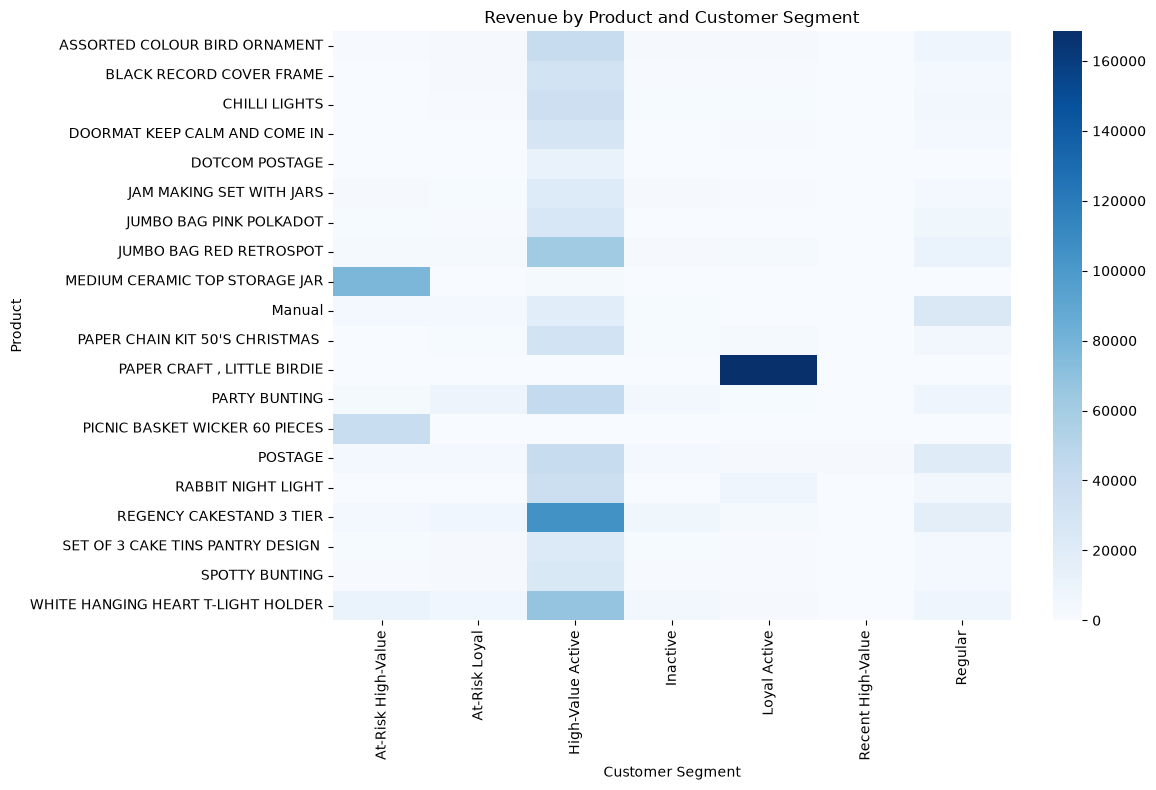

In [60]:
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    top_20_matrix,
    annot=False,
    cmap="Blues"
)

plt.title("Revenue by Product and Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [61]:
# Save product-segment analysis

product_segment.to_csv(
    "../data/processed/product_segment_analysis.csv",
    index=False
)

top_20_matrix.to_csv(
    "../data/processed/product_segment_matrix.csv"
)

print("Saved:")
print("- product_segment_analysis.csv")
print("- product_segment_matrix.csv")

Saved:
- product_segment_analysis.csv
- product_segment_matrix.csv


In [62]:
# Overall cancellation analysis

total_cancelled_units = cancellations["Quantity"].abs().sum()
total_cancellation_transactions = cancellations["InvoiceNo"].nunique()
total_cancellation_value = cancellations["Revenue"].abs().sum()

total_sales_units = sales["Quantity"].sum()
total_sales_revenue = sales["Revenue"].sum()

cancellation_unit_rate = (
    total_cancelled_units /
    (total_sales_units + total_cancelled_units)
) * 100

print("===== CANCELLATION ANALYSIS =====")
print(f"Cancelled units: {total_cancelled_units:,.0f}")
print(f"Cancellation transactions: {total_cancellation_transactions:,}")
print(f"Cancelled value: £{total_cancellation_value:,.2f}")
print(f"Cancellation unit rate: {cancellation_unit_rate:.2f}%")

===== CANCELLATION ANALYSIS =====
Cancelled units: 277,574
Cancellation transactions: 3,836
Cancelled value: £896,812.49
Cancellation unit rate: 4.74%


In [63]:
# Top products by cancelled units

top_cancelled_products = (
    cancellation_product
    .sort_values("Cancellation_Units", ascending=False)
    .head(20)
)

display(top_cancelled_products)

,StockCode,Description,Cancellation_Units,Cancellation_Transactions,Cancellation_Value
1529,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
1270,23166,MEDIUM CERAMIC TOP STORAGE JAR,74494,10,77479.64
1688,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9376,4,321.60
1972,M,Manual,4066,223,146784.46
133,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150,3,6591.42
96,20971,PINK BLUE FELT CRAFT TRINKET BOX,2617,4,2778.77
1859,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2578,42,6624.30
158,21175,GIN + TONIC DIET METAL SIGN,2030,7,3775.33
1079,22920,HERB MARKER BASIL,1527,2,841.05
624,22273,FELTCRAFT DOLL MOLLY,1447,5,3512.65


In [64]:
# Products with meaningful sales volume and high cancellation rates

high_volume_cancellation = product_performance[
    product_performance["Units_Sold"] >= 100
].copy()

high_volume_cancellation = (
    high_volume_cancellation
    .sort_values("Cancellation_Rate_%", ascending=False)
)

display(
    high_volume_cancellation[
        [
            "StockCode",
            "Description",
            "Units_Sold",
            "Revenue",
            "Cancellation_Units",
            "Cancellation_Transactions",
            "Cancellation_Rate_%"
        ]
    ].head(20)
)

,StockCode,Description,Units_Sold,Revenue,Cancellation_Units,Cancellation_Transactions,Cancellation_Rate_%
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,80995.0,1.0,50.000000
3163,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9461,26425.58,9376.0,4.0,49.774380
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,74494.0,10.0,48.839878
3755,85232B,SET OF 3 BABUSHKA STACKING TINS,274,1356.30,255.0,6.0,48.204159
2061,23113,PANTRY CHOPPING BOARD,1154,5868.50,946.0,6.0,45.047619
3537,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,235.35,73.0,2.0,41.011236
1993,23055,IVORY CHANDELIER T-LIGHT HOLDER,657,1395.18,432.0,5.0,39.669421
1996,23057,BEADED CHANDELIER T-LIGHT HOLDER,695,1420.97,433.0,6.0,38.386525
1995,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,960,2879.37,579.0,7.0,37.621832
2878,47566B,TEA TIME PARTY BUNTING,2379,11275.27,1424.0,7.0,37.444123


In [65]:
# Products with meaningful sales volume and high cancellation rates

high_volume_cancellation = product_performance[
    product_performance["Units_Sold"] >= 100
].copy()

high_volume_cancellation = (
    high_volume_cancellation
    .sort_values("Cancellation_Rate_%", ascending=False)
)

display(
    high_volume_cancellation[
        [
            "StockCode",
            "Description",
            "Units_Sold",
            "Revenue",
            "Cancellation_Units",
            "Cancellation_Transactions",
            "Cancellation_Rate_%"
        ]
    ].head(20)
)

,StockCode,Description,Units_Sold,Revenue,Cancellation_Units,Cancellation_Transactions,Cancellation_Rate_%
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,80995.0,1.0,50.000000
3163,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9461,26425.58,9376.0,4.0,49.774380
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,74494.0,10.0,48.839878
3755,85232B,SET OF 3 BABUSHKA STACKING TINS,274,1356.30,255.0,6.0,48.204159
2061,23113,PANTRY CHOPPING BOARD,1154,5868.50,946.0,6.0,45.047619
3537,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,235.35,73.0,2.0,41.011236
1993,23055,IVORY CHANDELIER T-LIGHT HOLDER,657,1395.18,432.0,5.0,39.669421
1996,23057,BEADED CHANDELIER T-LIGHT HOLDER,695,1420.97,433.0,6.0,38.386525
1995,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,960,2879.37,579.0,7.0,37.621832
2878,47566B,TEA TIME PARTY BUNTING,2379,11275.27,1424.0,7.0,37.444123


In [66]:
# High-revenue products with cancellation exposure

revenue_cancellation = (
    product_performance[
        product_performance["Revenue"] > 0
    ]
    .sort_values("Revenue", ascending=False)
    .head(50)
)

display(
    revenue_cancellation[
        [
            "StockCode",
            "Description",
            "Revenue",
            "Units_Sold",
            "Orders",
            "Cancellation_Units",
            "Cancellation_Value",
            "Cancellation_Rate_%"
        ]
    ]
)

,StockCode,Description,Revenue,Units_Sold,Orders,Cancellation_Units,Cancellation_Value,Cancellation_Rate_%
4150,DOT,DOTCOM POSTAGE,206248.77,706,706,1.0,3.29,0.141443
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,857.0,9722.55,5.826761
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,80995.0,168469.60,50.000000
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189,2578.0,6624.30,6.419642
2877,47566,PARTY BUNTING,99445.23,18283,1685,277.0,1201.35,1.492457
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,1115.0,1984.02,2.253163
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,74494.0,77479.64,48.839878
4153,POST,POSTAGE,78101.88,3150,1126,147.0,11871.24,4.458599
4151,M,Manual,77750.27,6984,289,4066.0,146784.46,36.796380
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,108.0,208.40,0.350115


In [67]:
# Monthly cancellation trend

cancellations["YearMonth"] = (
    cancellations["InvoiceDate"].dt.to_period("M")
)

monthly_cancellations = (
    cancellations
    .groupby("YearMonth")
    .agg(
        Cancelled_Units=("Quantity", lambda x: x.abs().sum()),
        Cancellation_Transactions=("InvoiceNo", "nunique"),
        Cancelled_Value=("Revenue", lambda x: x.abs().sum())
    )
    .reset_index()
)

display(monthly_cancellations)

,YearMonth,Cancelled_Units,Cancellation_Transactions,Cancelled_Value
0,2010-12,16042,326,74789.12
1,2011-01,79845,260,131364.30
2,2011-02,2871,219,25569.24
3,2011-03,5395,318,34372.28
4,2011-04,13645,240,44601.50
5,2011-05,5868,314,47202.51
6,2011-06,7362,329,70616.78
7,2011-07,6028,270,37921.08
8,2011-08,12346,278,54333.75
9,2011-09,7429,333,38902.55


In [68]:
# Combine monthly sales and cancellation metrics

monthly_sales_summary = (
    sales
    .groupby(sales["InvoiceDate"].dt.to_period("M"))
    .agg(
        Sales_Revenue=("Revenue", "sum"),
        Sales_Units=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
    .rename(columns={"InvoiceDate": "YearMonth"})
)

monthly_cancellation_summary = monthly_cancellations.rename(
    columns={"YearMonth": "YearMonth"}
)

monthly_business_health = monthly_sales_summary.merge(
    monthly_cancellation_summary,
    on="YearMonth",
    how="left"
).fillna(0)

monthly_business_health["Cancellation_Rate_%"] = (
    monthly_business_health["Cancelled_Units"] /
    (
        monthly_business_health["Sales_Units"] +
        monthly_business_health["Cancelled_Units"]
    )
) * 100

display(monthly_business_health)

,YearMonth,Sales_Revenue,Sales_Units,Orders,Cancelled_Units,Cancellation_Transactions,Cancelled_Value,Cancellation_Rate_%
0,2010-12,821452.730,358019,1559,16042,326,74789.12,4.288605
1,2011-01,689811.610,387099,1086,79845,260,131364.30,17.099481
2,2011-02,522545.560,282934,1100,2871,219,25569.24,1.004531
3,2011-03,716215.260,376599,1454,5395,318,34372.28,1.412326
4,2011-04,536968.491,307953,1246,13645,240,44601.50,4.242875
5,2011-05,769296.610,395001,1681,5868,314,47202.51,1.463820
6,2011-06,760547.010,388511,1533,7362,329,70616.78,1.859687
7,2011-07,718076.121,399693,1476,6028,270,37921.08,1.485750
8,2011-08,757841.380,421020,1361,12346,278,54333.75,2.848862
9,2011-09,1056435.192,569573,1838,7429,333,38902.55,1.287517


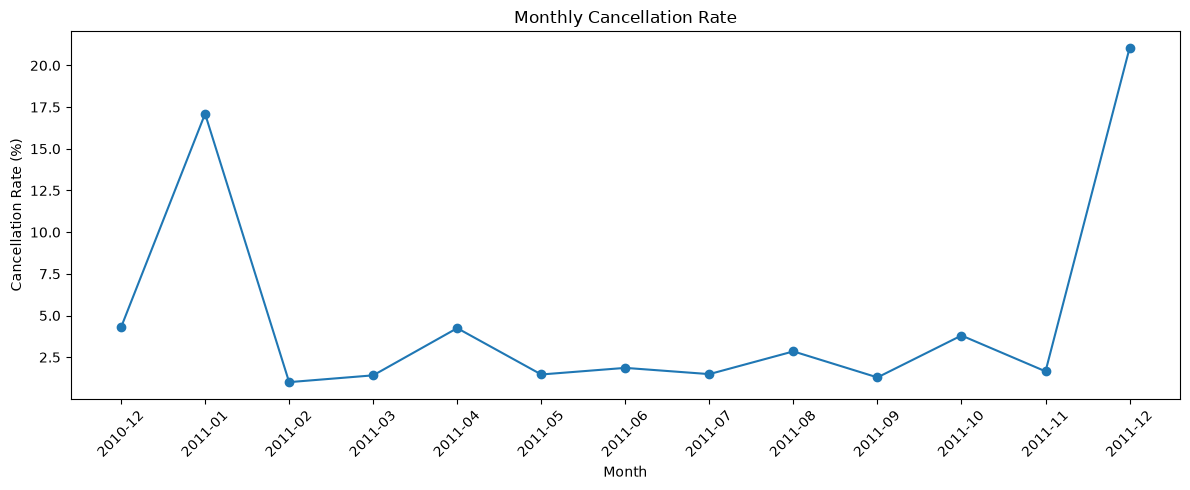

In [69]:
# Monthly cancellation trend

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_business_health["YearMonth"].astype(str),
    monthly_business_health["Cancellation_Rate_%"],
    marker="o"
)

plt.title("Monthly Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [70]:
# Save cancellation analysis

monthly_business_health.to_csv(
    "../data/processed/monthly_business_health.csv",
    index=False
)

high_volume_cancellation.to_csv(
    "../data/processed/high_volume_cancellation_products.csv",
    index=False
)

print("Cancellation analysis files saved.")

Cancellation analysis files saved.


In [71]:
# Identify non-product/service items
non_product_keywords = [
    "POSTAGE",
    "MANUAL",
    "DOTCOM",
    "BANK CHARGES",
    "AMAZON FEE",
    "CARRIAGE",
    "DISCOUNT"
]

non_product_mask = (
    product_performance["Description"]
    .fillna("")
    .str.upper()
    .str.contains("|".join(non_product_keywords), regex=True)
)

print("Non-product/service items identified:", non_product_mask.sum())

display(
    product_performance.loc[
        non_product_mask,
        ["StockCode", "Description", "Revenue"]
    ].sort_values("Revenue", ascending=False).head(20)
)

Non-product/service items identified: 18


,StockCode,Description,Revenue
4150,DOT,DOTCOM POSTAGE,206248.770
4153,POST,POSTAGE,78101.880
4151,M,Manual,77750.270
4139,AMAZONFEE,AMAZON FEE,13761.090
4142,C2,CARRIAGE,7051.000
2445,23444,Next Day Carriage,1200.000
2043,23099,FRENCH CARRIAGE LANTERN,925.350
3686,85168B,BLACK BAROQUE CARRIAGE CLOCK,432.790
4157,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,175.530
4159,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,167.560


In [72]:
# Keep only actual products
product_sales = product_performance.loc[
    ~non_product_mask
].copy()

print("Total product records:", len(product_sales))

print("\nTop 10 actual products by revenue:")

display(
    product_sales
    .sort_values("Revenue", ascending=False)
    .head(10)
)

Total product records: 4143

Top 10 actual products by revenue:


,StockCode,Description,Revenue,Units_Sold,Orders,Avg_Unit_Price,Cancellation_Units,Cancellation_Transactions,Cancellation_Value,Cancellation_Rate_%
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,13.983936,857.0,180.0,9722.55,5.826761
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,2.080000,80995.0,1.0,168469.60,50.000000
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189,3.116159,2578.0,42.0,6624.30,6.419642
2877,47566,PARTY BUNTING,99445.23,18283,1685,5.797928,277.0,20.0,1201.35,1.492457
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,2.486197,1115.0,43.0,1984.02,2.253163
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,1.468480,74494.0,10.0,77479.64,48.839878
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,2.386401,108.0,15.0,208.40,0.350115
1022,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,3.362331,453.0,10.0,1160.35,2.289961
3416,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,1.722575,80.0,12.0,135.20,0.219527
3059,79321,CHILLI LIGHTS,54096.36,10302,661,6.795397,80.0,6.0,349.70,0.770564


In [73]:
# Product health metrics

product_sales["Cancellation_Rate_%"] = (
    product_sales["Cancellation_Units"]
    / (
        product_sales["Units_Sold"]
        + product_sales["Cancellation_Units"]
    )
    * 100
)

# Products with meaningful sales volume
product_health = product_sales[
    product_sales["Units_Sold"] >= 100
].copy()

print("Products after minimum volume filter:", len(product_health))

display(
    product_health[
        [
            "StockCode",
            "Description",
            "Revenue",
            "Units_Sold",
            "Orders",
            "Cancellation_Rate_%"
        ]
    ]
    .sort_values("Cancellation_Rate_%", ascending=False)
    .head(15)
)

Products after minimum volume filter: 2766


,StockCode,Description,Revenue,Units_Sold,Orders,Cancellation_Rate_%
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,50.000000
3163,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,26425.58,9461,449,49.774380
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,48.839878
3755,85232B,SET OF 3 BABUSHKA STACKING TINS,1356.30,274,13,48.204159
2061,23113,PANTRY CHOPPING BOARD,5868.50,1154,57,45.047619
3537,85023B,EAU DE NILE JEWELLED PHOTOFRAME,235.35,105,13,41.011236
1993,23055,IVORY CHANDELIER T-LIGHT HOLDER,1395.18,657,38,39.669421
1996,23057,BEADED CHANDELIER T-LIGHT HOLDER,1420.97,695,38,38.386525
1995,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,2879.37,960,38,37.621832
2878,47566B,TEA TIME PARTY BUNTING,11275.27,2379,365,37.444123


In [74]:
# Product risk analysis

revenue_median = product_health["Revenue"].median()
cancellation_median = product_health["Cancellation_Rate_%"].median()

product_health["Revenue_Level"] = (
    product_health["Revenue"]
    .apply(lambda x: "High Revenue" if x >= revenue_median else "Low Revenue")
)

product_health["Cancellation_Level"] = (
    product_health["Cancellation_Rate_%"]
    .apply(
        lambda x: "High Cancellation"
        if x >= cancellation_median
        else "Low Cancellation"
    )
)

product_health["Product_Risk_Segment"] = (
    product_health["Revenue_Level"]
    + " + "
    + product_health["Cancellation_Level"]
)

print("Revenue median:", round(revenue_median, 2))
print("Cancellation-rate median:", round(cancellation_median, 2))

display(
    product_health[
        product_health["Product_Risk_Segment"]
        == "High Revenue + High Cancellation"
    ][
        [
            "StockCode",
            "Description",
            "Revenue",
            "Units_Sold",
            "Orders",
            "Cancellation_Rate_%",
            "Product_Risk_Segment"
        ]
    ]
    .sort_values("Revenue", ascending=False)
    .head(20)
)

Revenue median: 1366.22
Cancellation-rate median: 0.43


,StockCode,Description,Revenue,Units_Sold,Orders,Cancellation_Rate_%,Product_Risk_Segment
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,5.826761,High Revenue + High Cancellation
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,50.000000,High Revenue + High Cancellation
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189,6.419642,High Revenue + High Cancellation
2877,47566,PARTY BUNTING,99445.23,18283,1685,1.492457,High Revenue + High Cancellation
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,2.253163,High Revenue + High Cancellation
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,48.839878,High Revenue + High Cancellation
1022,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,2.289961,High Revenue + High Cancellation
3059,79321,CHILLI LIGHTS,54096.36,10302,661,0.770564,High Revenue + High Cancellation
2285,23298,SPOTTY BUNTING,42513.48,8320,1140,1.304864,High Revenue + High Cancellation
1307,22386,JUMBO BAG PINK POLKADOT,42401.01,21448,1218,2.081812,High Revenue + High Cancellation


In [75]:
# Save product health analysis for the dashboard

product_health.to_csv(
    "../data/processed/product_health.csv",
    index=False
)

print("Saved: product_health.csv")
print("Shape:", product_health.shape)

Saved: product_health.csv
Shape: (2766, 13)
